# PHÂN TÍCH DỮ LIỆU ÂM NHẠC FMA


Thông tin cá nhân:
- Họ tên: Đoàn Minh Huy
- MSSV: 24700701

## 1. Giới thiệu đề tài

### 1.1. Bối cảnh và lý do chọn đề tài
- Về bối cảnh: Âm nhạc ngày càng gắn với các nên tảng số. Mỗi bài hát không chỉ có thông tin như tên, nghệ sĩ, thể loại,... mà còn có những đặc trung âm nhạc có thể định lượng và phân tích.
- Về vấn đề: Liệu các thể loại nhạc có sự khác biệt về đặc trung âm thanh? Có thể sử dụng dữ liệu metadata để có thể khám phá những điểm tương đồng, phân nhóm và phân loại bài hát không?
- Về lý do chọn dataset FMA: Dataset có quy mô lớn, hơn 100000 bài hát, cung cấp metadata nhãn thể loại và các đặc trung âm thanh đã trích xuất phù hợp với nhiều kỹ thuật phân tích dữ liệu (đề tài chỉ sử dụng metadata để phân tích, không sử dụng file âm thanh)
- Về lý do cá nhân: Do bản thân em khá yêu thích âm nhạc vì vậy có hứng thú và muốn thử dùng kiến thức Phân tích dữ liệu để dùng vào một lĩnh vực mà mình hứng thú.

### 1.2. Mục tiêu
Đề tài được thực hiện trong khuôn khổ bài tập cá nhân của môn Nhập môn phân tích dữ liệu và AI, vì vậy với mục tiêu là vận dụng kiến thức và kỹ thuật đã học vào quá trình phân tích một bộ dữ liệu thực tế. 

Các mục tiêu sẽ bao gồm:
- Khám phá và tiền xử lý dữ liệu: TÌm hiểu cấu trúc dữ liệu, xây dựng ERD, đánh giá chất lượng dữ liệu và thực hiện các bước làm sách, chuẩn bị dữ liệu phục vụ phân tích
- Phân tích thống kê và trực quan hóa: Áp dụng thống kê mô tả, biểu đồ thống kê, phân phối xác suất và kiểm định giả thuyết để khám phá đặc điểm và các mối quan hệ trong dữ liệu âm nhạc.
- Ứng dụng các thuật toán máy học: Thực hiện hồi quy, phân loại, phân cụm và giảm chiều dữ liệu bằng các phương pháp đã học nhằm khám phá đặc trung âm thanh và đánh giá kết quả mô hình
- Ứng dụng luật kết hợp: Tìm hiểu mối quan hệ đồng nhất xuất hiện giữa những thể loại và đánh giá kết quả mô hình.
- Đánh giá và tổng hợp kết quả: Diễn giải các kết quả phân tích và đánh giá ưu điểm hạn chế của từng phương pháp và rút ra những nhận xét dựa trên dữ liệu thực tế.


## 2. Tổng quan và khám phá dữ liệu

### 2.1. Giới thiệu bộ dữ liệu Free Music Archive (FMA)
Bộ dữ liệu FMA - Free Music Archive hay tên đầy đủ là "FMA: A Dataset For Music Analysis" được tặng cho UCI vào 2017, đây là bộ dữ liệu được làm ra bởi M. Deferrard, K. Benzi, P. Vandergheynst và X. Bresson với mã số DOI là 10.24432/C5HW28. FMA có 106.574 bài hát bao gồm tiêu đề, albume, artist, genres...

Nguồn: [FMA Dataset](https://archive.ics.uci.edu/dataset/386/fma+a+dataset+for+music+analysis)

### 2.2. Mô tả cấu trúc các bảng dữ liệu
Bộ dữ liệu FMA có tổng cộng 8 files csv, gồm 4 file raw và 4 file đã được làm sạch tương đối từ tác giả, trong đề tài này em sẽ sử dụng 4 file sạch tương đối bao gồm ***tracks.csv***, ***echonest.csv***, ***features.csv***, ***genres.csv***. Mỗi bảng cung cấp một nhóm thông tin khác nhau về bài hát, đặc trưng âm thanh hoặc thể loại âm nhạc.

| Bảng Dữ Liệu | Số bản ghi (Dòng) | Số thuộc tính (Cột) | Nội dung |
|:---:|:---:|:---:|:---:|
| tracks.csv | 106.574 | 52 | Metadata về bài hát, albume, nghệ sĩ và thể loại |
| features.csv | 106.574 | 518 | Các đặc trưng âm thanh được trích xuất từ bài hát |
| echonest.csv | 13.129 | 249 | Các thuộc tính và đặc trưng âm thanh bổ sung từ Echo Nest |
| genres.csv | 163 | 5 | Danh mục thể loại và quan hệ phân cấp giữa các thể loại |

#### Hàng và Cột của các bảng
![Hàng và Cột đã được kiểm tra](../image/Col_Row.png)

#### Tổng quan các bảng
##### Bảng Tracks
Bảng tracks.csv chưa metadata của các bài hát bao gồm thông tin về bài hát, albume, nghệ sĩ, thể loại,...

Một vài thuộc tính (cột) tiêu biểu: 
| Thuộc tính | Ý nghĩa |
|:---:|:---:|
| track_id | Id bài hát |
| track.title | Tên bài hát |
| track.duration | Thời lượng |
| track.genre_top | Thể loại chính |
| track.genres_all | Tất cả thể loại liên quan |
| album.title | Tên albume |
| artisit.name | Tên nghệ sĩ |
| set.subset | Tập dữ liệu con của bài hát |

Bảng sử dụng cột hai cấp giúp phân nhóm các thuộc tính theo đối tượng.
![Bảng check Tracks 1](../image/sampleTracks1.png)

##### Bảng Features
Bảng features.csv chứa 518 đặc trưng của âm thanh đã được trích xuất, có thể ứng dụng vào các bài toán phân tích, phân cụm, phân loại và giảm chiều dữ liệu

Một vài thuộc tính (cột) tiêu biểu: 
| Thuộc tính | Ý nghĩa |
|:---:|:---:|
| mfcc | Hệ số biểu diễn đặc điểm phổ âm |
| chroma_cens | Đặc trưng phân bố cao độ |
| spectral_centroid | Đặc trưng trọng tâm phổ |
| spectral_contrast | Đjăc trưng độ tương phản phổ |
| tonnetz | Đặc trưng quan hệ hòa âm |
| zcr | Đặc trưng tỷ lệ đổi dấu tín hiệu|

![Bảng check Features 1](../image/sampleFeatures1.png)
##### Bảng Echonest
Bảng echonest.csv cung cấp thông tin phân tihcs âm thanh bổ sung từ Echo Nest, gồm các thuộc tính như danceability, energy, acousticness, ...

Bảng chỉ có dữ liệu cho 13.129 bài hát, do đó mức độ bao phủ thấp hơn so với tracks.csv và features.csv.

##### Bảng Genres
Bảng genres.csv chứa thông tin về 163 thể loại âm nhạc, gồm năm thuộc tính:

| Thuộc tính | Ý nghĩa |
|:---:|:---:|
| genre_id | Id thể loại |
| title | Tên thể loại |
| parent | Id thể loại cha |
| top_level | Id thể loại cấp cao nhất |
| #tracks | Số bài hát được gắn với thể loại |

![Bảng check Genres 1](../image/sampleGenres1.png)

[ipynb kiểm tra](../notebooks/sideNotebooks/sideNotebook.ipynb.ipynb)


### 2.3. Sơ đồ ERD
![ERD](../image/erd.png)

ERD được xây dựng mwor mức logic, chỉ thể hiện các thuộc tính tiêu biểu để trực quan dễ theo dõi. Các bảng Track, Feature, Echonest chứa nhiều thuộc tính hơn sơ đồ trên, bên cạnh đó mfcc, chroma_cens, spectral_centroid, spectral_contrast, tonnetz, zcr đại diện cho các nhóm đặc trung âm thanh, không phải là các thuộc tính đơn lẻ

TRACK_GENRE là bảng trung gian được em thêm vào để biểu diễn quan hệ n-n giữa bài hát và thể loại, không phải bảng có sẵn.

Mô tả liên kết:
- TRACK là thực thể trung tâm, sử dụng track_id làm khóa chính để định danh cho bài hát
- FEATURES và ECHONEST liên kết với TRACKS thông qua track_id, cung cấp những đặc trung âm thanh tương ứng với bài hát
- GENRE chứa thông tin các thể loại âm nahcj, dùng genre_id làm khóa chính và parent để biểu diễn quan hệ phân cấp giữa các thể loại
- Một bài hát có thể được gắn nhiều thể loại và một thể loại có thể xuất hiện ở nhiều bài hát nên em đã thên bảng trung gian TRACK_GENRE vào

Mô tả cardinality:
| Quan hệ | Bội số | Giải thích |
|:---:|:---:|:---:|
| TRACK-FEATURE | 1-0..1 | Một bài hát có tối đa một bản ghi đặc trưng âm thanh; mỗi bản ghi đặc trưng thuộc một bài hát |
| TRACK-ECHONEST | 1-0..1 | Một bài hát có thể có hoặc không có dữ liệu Echo Nest. |
| TRACK-TRACK_GENRE | 1-0..n | Một bài hát có thể liên kết với nhiều thể loại. |
| GENRE-TRACK_GENRE | 1-0..n | Một thể loại có thể được gắn với nhiều bài hát |
| GENRE-GENRE | 0..1-0..n | Một thể loại có tối đa một thể loại cha và có thể có nhiều thể loại con |

### 2.4. Nạp dữ liệu vào Pandas

Dùng thư viện Pandas để đẩy dữ liệu của các file csv vào DataFrame tương úng, do cấu trúc tiêu đề của các bảng không đồng nhất nên phải sử dụng thêm header và index_col được thiết lập phù hợp để bảo toàn tên thuộc tính và id như track_id

In [36]:
import pandas as pd

DATA_DIR = "../data/raw/fma_metadata/"

tracks = pd.read_csv(DATA_DIR + "tracks.csv", index_col=0, header=[0, 1])
features = pd.read_csv(DATA_DIR + "features.csv", index_col=0, header=[0, 1, 2])
echonest = pd.read_csv(DATA_DIR + "echonest.csv", index_col=0, header=[0, 1, 2])
genres = pd.read_csv(DATA_DIR + "genres.csv")

print("Hàng và Cột của bảng Tracks:", tracks.shape)
print("Hàng và Cột của bảng Features:", features.shape)
print("Hàng và Cột của bảng Echonest:", echonest.shape)
print("Hàng và Cột của bảng Genres:", genres.shape)

print("Bảng Tracks: ")
display(tracks.head())

print("Bảng Features: ")
display(features.head())

print("Bảng Echonest: ")
display(echonest.head())

print("Bảng Genres: ")
display(genres.head())


Hàng và Cột của bảng Tracks: (106574, 52)
Hàng và Cột của bảng Features: (106574, 518)
Hàng và Cột của bảng Echonest: (13129, 249)
Hàng và Cột của bảng Genres: (163, 5)
Bảng Tracks: 


album                                                     \
         comments         date_created        date_released engineer   
track_id                                                               
2               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
3               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
5               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
10              0  2008-11-26 01:45:08  2008-02-06 00:00:00      NaN   
20              0  2008-11-26 01:45:05  2009-01-06 00:00:00      NaN   

                                                                          \
         favorites id                                information listens   
track_id                                                                   
2                4  1                                    <p></p>    6073   
3                4  1                                    <p></p>    6073   
5                4  1                                    <p></p>    6073   
10               4  6                                        NaN   47632   
20               2  4  <p> "spiritual songs" from Nicky Cook</p>    2710   

                        ...       track                         \
         producer tags  ... information interest language_code   
track_id                ...                                      
2             NaN   []  ...         NaN     4656            en   
3             NaN   []  ...         NaN     1470            en   
5             NaN   []  ...         NaN     1933            en   
10            NaN   []  ...         NaN    54881            en   
20            NaN   []  ...         NaN      978            en   

                                                                              \
                                                    license listens lyricist   
track_id                                                                       
2         Attribution-NonCommercial-ShareAlike 3.0 Inter...    1293      NaN   
3         Attribution-NonCommercial-ShareAlike 3.0 Inter...     514      NaN   
5         Attribution-NonCommercial-ShareAlike 3.0 Inter...    1151      NaN   
10        Attribution-NonCommercial-NoDerivatives (aka M...   50135      NaN   
20        Attribution-NonCommercial-NoDerivatives (aka M...     361      NaN   

                                                 
         number publisher tags            title  
track_id                                         
2             3       NaN   []             Food  
3             4       NaN   []     Electric Ave  
5             6       NaN   []       This World  
10            1       NaN   []          Freeway  
20            3       NaN   []  Spiritual Level  

[5 rows x 52 columns]

Bảng Features: 


feature    chroma_cens                                                    \
statistics    kurtosis                                                     
number              01        02        03        04        05        06   
track_id                                                                   
2             7.180653  5.230309  0.249321  1.347620  1.482478  0.531371   
3             1.888963  0.760539  0.345297  2.295201  1.654031  0.067592   
5             0.527563 -0.077654 -0.279610  0.685883  1.937570  0.880839   
10            3.702245 -0.291193  2.196742 -0.234449  1.367364  0.998411   
20           -0.193837 -0.198527  0.201546  0.258556  0.775204  0.084794   

feature                                             ...   tonnetz            \
statistics                                          ...       std             
number            07        08        09        10  ...        04        05   
track_id                                            ...                       
2           1.481593  2.691455  0.866868  1.341231  ...  0.054125  0.012226   
3           1.366848  1.054094  0.108103  0.619185  ...  0.063831  0.014212   
5          -0.923192 -0.927232  0.666617  1.038546  ...  0.040730  0.012691   
10          1.770694  1.604566  0.521217  1.982386  ...  0.074358  0.017952   
20         -0.289294 -0.816410  0.043851 -0.804761  ...  0.095003  0.022492   

feature                     zcr                                          \
statistics             kurtosis       max      mean    median       min   
number            06         01        01        01        01        01   
track_id                                                                  
2           0.012111   5.758890  0.459473  0.085629  0.071289  0.000000   
3           0.017740   2.824694  0.466309  0.084578  0.063965  0.000000   
5           0.014759   6.808415  0.375000  0.053114  0.041504  0.000000   
10          0.013921  21.434212  0.452148  0.077515  0.071777  0.000000   
20          0.021355  16.669037  0.469727  0.047225  0.040039  0.000977   

feature                         
statistics      skew       std  
number            01        01  
track_id                        
2           2.089872  0.061448  
3           1.716724  0.069330  
5           2.193303  0.044861  
10          3.542325  0.040800  
20          3.189831  0.030993  

[5 rows x 518 columns]

Bảng Echonest: 


echonest                                                    \
         audio_features                                                     
           acousticness danceability    energy instrumentalness  liveness   
track_id                                                                    
2              0.416675     0.675894  0.634476         0.010628  0.177647   
3              0.374408     0.528643  0.817461         0.001851  0.105880   
5              0.043567     0.745566  0.701470         0.000697  0.373143   
10             0.951670     0.658179  0.924525         0.965427  0.115474   
134            0.452217     0.513238  0.560410         0.019443  0.096567   

                                                                        ...  \
                                           metadata                     ...   
         speechiness    tempo   valence  album_date         album_name  ...   
track_id                                                                ...   
2           0.159310  165.922  0.576661         NaN                NaN  ...   
3           0.461818  126.957  0.269240         NaN                NaN  ...   
5           0.124595  100.260  0.621661         NaN                NaN  ...   
10          0.032985  111.562  0.963590  2008-03-11  Constant Hitmaker  ...   
134         0.525519  114.290  0.894072         NaN                NaN  ...   

                                                                              \
         temporal_features                                                     
                       214        215       216       217       218      219   
track_id                                                                       
2                -1.992303   6.805694  0.233070  0.192880  0.027455  0.06408   
3                -1.582331   8.889308  0.258464  0.220905  0.081368  0.06413   
5                -2.288358  11.527109  0.256821  0.237820  0.060122  0.06014   
10               -3.662988  21.508228  0.283352  0.267070  0.125704  0.08082   
134              -1.452696   2.356398  0.234686  0.199550  0.149332  0.06440   

                                                     
                                                     
               220       221        222         223  
track_id                                             
2          3.67696   3.61288  13.316690  262.929749  
3          6.08277   6.01864  16.673548  325.581085  
5          5.92649   5.86635  16.013849  356.755737  
10         8.41401   8.33319  21.317064  483.403809  
134       11.26707  11.20267  26.454180  751.147705  

[5 rows x 249 columns]

Bảng Genres: 


,genre_id,#tracks,parent,title,top_level
0,1,8693,38,Avant-Garde,38
1,2,5271,0,International,2
2,3,1752,0,Blues,3
3,4,4126,0,Jazz,4
4,5,4106,0,Classical,5


### 2.5. Khám phá thông tin tổng quan

Sau khi đã có dữ liệu, tiến hành khám phá thông tin tổng quan thông qua các phương thức info(), describe(), value_counts() để xác định cấu trúc, kiểu dữ liệu và đặc điểm thống kê ban đầu của dữ liệu

Do features và echonest có số lượng thuộc tính lớn, chỉ mốt số thuộc tính tiêu được mới được lựa chọn để hiển thị kết quả thống kê nhằm khiến cho nội dung dễ quan sát và tránh hiển thị bảng dữ liệu quá rối

### Kiểm tra thông tin tổng quan

In [37]:
print("Bảng Tracks:")
tracks.info(verbose=False)

print("\nBảng Features:")
features.info(verbose=False)

print("\nBảng Echonest:")
echonest.info(verbose=False)

print("\nBảng Genres:")
genres.info(verbose=False) #verbose dùng tóm tắt tông tin về kích  thước, nhóm dữ liệu bộ nhứo


Bảng Tracks:
<class 'pandas.DataFrame'>
Index: 106574 entries, 2 to 155320
Columns: 52 entries, ('album', 'comments') to ('track', 'title')
dtypes: float64(2), int64(15), str(35)
memory usage: 43.1 MB

Bảng Features:
<class 'pandas.DataFrame'>
Index: 106574 entries, 2 to 155320
Columns: 518 entries, ('chroma_cens', 'kurtosis', '01') to ('zcr', 'std', '01')
dtypes: float64(518)
memory usage: 422.0 MB

Bảng Echonest:
<class 'pandas.DataFrame'>
Index: 13129 entries, 2 to 124911
Columns: 249 entries, ('echonest', 'audio_features', 'acousticness') to ('echonest', 'temporal_features', '223')
dtypes: float64(244), str(5)
memory usage: 25.0 MB

Bảng Genres:
<class 'pandas.DataFrame'>
RangeIndex: 163 entries, 0 to 162
Columns: 5 entries, genre_id to top_level
dtypes: int64(4), str(1)
memory usage: 6.5 KB


### Thống kê tổng quan

#### tracks.csv
Xem nhanh thời lượng và lượt nghe của bài hát thông qua các chỉ số

In [38]:


display(tracks[[
    ("track", "duration"),
    ("track", "listens")
]].describe().round(2))



track           
        duration    listens
count  106574.00  106574.00
mean      277.85    2329.35
std       305.52    8028.07
min         0.00       0.00
25%       149.00     292.00
50%       216.00     764.00
75%       305.00    2018.00
max     18350.00  543252.00

#### features.csv
Chỉ lấy 5 cột đầu tiên để minh họa thống kê vì đây là dữ liệu nhóm

In [39]:

display(features.iloc[:, :5].describe().round(2))


feature    chroma_cens                                            
statistics    kurtosis                                            
number              01         02         03         04         05
count        106574.00  106574.00  106574.00  106574.00  106574.00
mean              0.44       0.20       0.33       0.27       0.29
std              32.29      11.12       9.98      19.07      15.03
min              -1.96      -1.94      -1.97      -3.00      -1.92
25%              -0.64      -0.67      -0.63      -0.64      -0.66
50%              -0.18      -0.22      -0.15      -0.19      -0.20
75%               0.49       0.41       0.53       0.45       0.45
max            8843.37    2864.08    1777.62    4257.05    3188.03

#### echonest.csv
Chỉ lấy 5 cột đầu tiên để minh họa vì là dữ liệu nhóm

In [40]:

display(echonest.iloc[:, :5].describe().round(2))


echonest                                                  
      audio_features                                                  
        acousticness danceability    energy instrumentalness  liveness
count       13129.00     13129.00  13129.00         13129.00  13129.00
mean            0.52         0.49      0.54             0.64      0.19
std             0.38         0.19      0.28             0.36      0.16
min             0.00         0.05      0.00             0.00      0.03
25%             0.10         0.34      0.32             0.32      0.10
50%             0.57         0.49      0.55             0.84      0.12
75%             0.92         0.63      0.78             0.92      0.21
max             1.00         0.97      1.00             1.00      0.98

#### genres.csv
Khám phá sơ phân bố số bài hát với từng thể loại

In [41]:

display(genres[["#tracks"]].describe().round(2))


,#tracks
count,163.00
mean,2142.09
std,5199.54
min,0.00
25%,125.00
50%,563.00
75%,1846.50
max,38154.00


### Khám phá một số thuộc tính khác

In [42]:
display(tracks[[
    ("track", "genre_top"),
    ("set", "subset")
]].describe())


,track,set
,genre_top,subset
count,49598,106574
unique,16,3
top,Rock,large
freq,14182,81574


In [43]:

display(
    tracks[("set", "subset")]
    .value_counts()
    .to_frame("Số bài hát")
)


,Số bài hát
"(set, subset)",
large,81574
medium,17000
small,8000


### 2.6. Truy vấn dữ liệu có điều kiện

Sử dụng các phép so sánh và hàm lọc dữ liệu để truy xuất những bản ghi thỏa mãn yêu cầu cụ thể. Các truy vấn được thực hiện trên thông tin của bài hát và thể loại để khám phá những nhóm dữ liệu cần quan tâm.

#### Truy vấn theo một điều kiện
Liệt kê các bài hát có thời lượng lớn hơn 300 giây (5 phút)

In [44]:

long_tracks = tracks[tracks[("track", "duration")] > 300]

display(long_tracks[[
    ("track", "title"),
    ("track", "duration"),
    ("artist", "name")
]].head(10))

print("Số bài hát thỏa điều kiện:", len(long_tracks))


track           \
                                                 title duration   
track_id                                                          
20                                     Spiritual Level      311   
135                                       Father's Day      837   
136                         Peel Back The Mountain Sky      509   
137                                             Side A     1233   
138                                             Side B     1231   
142                               Punjabi Watery Grave      470   
145                                         Amoebiasis      326   
146       Gimme a Buck or I'll Touch You / Boilermaker      354   
149                  Outside the window bees buzzed...      988   
150       ... listening to the sunshine burn the grass     1182   

                                   artist  
                                     name  
track_id                                   
20                             Nicky Cook  
135                              Abominog  
136                              Abominog  
137                                Airway  
138                                Airway  
142       Alec K. Redfearn & the Eyesores  
145                      Amoebic Ensemble  
146                      Amoebic Ensemble  
149                          Andy Hayleck  
150                          Andy Hayleck

Số bài hát thỏa điều kiện: 27723


#### Truy vấn theo thuộc tính định tính
Liệt kê các bài hát có thể loại chính là Rock

In [45]:

rock_tracks = tracks[tracks[("track", "genre_top")] == "Rock"]

display(rock_tracks[[
    ("track", "title"),
    ("track", "genre_top"),
    ("artist", "name")
]].head(10))

print("Số bài hát thuộc Rock:", len(rock_tracks))


track                    artist
                               title genre_top            name
track_id                                                      
135                     Father's Day      Rock        Abominog
136       Peel Back The Mountain Sky      Rock        Abominog
151                      Untitled 04      Rock   Animal Writes
152                      Untitled 11      Rock   Animal Writes
153               Hundred-Year Flood      Rock  Arc and Sender
154              Squares And Circles      Rock  Arc and Sender
155          Maps of the Stars Homes      Rock  Arc and Sender
169                     Boss of Goth      Rock      Argumentix
170       Industry Standard Massacre      Rock      Argumentix
171          Marching as Technitions      Rock      Argumentix

Số bài hát thuộc Rock: 14182


#### Truy vấn đa điều kiện
Liệt kê các bài hát Rock có thời lượng từ 180 đến 300 giây

In [46]:

# Kết hợp điều kiện thể loại và thời lượng
rock_duration = tracks[
    (tracks[("track", "genre_top")] == "Rock") &
    (tracks[("track", "duration")] >= 180) &
    (tracks[("track", "duration")] <= 300)
]

display(rock_duration[[
    ("track", "title"),
    ("track", "duration"),
    ("track", "genre_top")
]].head(10))

print("Số bài hát thỏa điều kiện:", len(rock_duration))



track                   
                                                     title duration genre_top
track_id                                                                     
151                                            Untitled 04      192      Rock
152                                            Untitled 11      193      Rock
170                             Industry Standard Massacre      181      Rock
172                             I Can't Stand You Up-right      206      Rock
173       Save Life's Golden Receipt In Case Refund Needed      218      Rock
174                                       Senator's Stance      199      Rock
178                                      Lend Me a Blanket      259      Rock
182                                  Jules Lost His Jewels      228      Rock
183                                        For Kate I Wait      260      Rock
184                                                  Helen      254      Rock

Số bài hát thỏa điều kiện: 5340


#### Truy vấn bằng .loc trên Genres
Liệt kê các thể loại âm nhạc cấp cao nhất, tức những thể loại không có thể loại cha

In [47]:

# Các thể loại không có thể loại cha
top_genres = genres.loc[genres["parent"] == 0]

display(top_genres[[
    "genre_id",
    "title",
    "parent",
    "top_level",
    "#tracks"
]].head(10))

print("Số thể loại cấp cao nhất:", len(top_genres))


,genre_id,title,parent,top_level,#tracks
1,2,International,0,2,5271
2,3,Blues,0,3,1752
3,4,Jazz,0,4,4126
4,5,Classical,0,5,4106
7,8,Old-Time / Historic,0,8,868
8,9,Country,0,9,1987
9,10,Pop,0,10,13845
11,12,Rock,0,12,32923
12,13,Easy Listening,0,13,730
13,14,Soul-RnB,0,14,1499


Số thể loại cấp cao nhất: 16


Các phép truy vấn cho phép trích xuất những nhóm bản ghi theo điều kiện về thời lượng của bản nhạc, thể loại và cấu trúc phân cấp thể loại âm nhạc. Khi kết hợp đa điều kiện, phạm vi dữ liệu cần quan sát được thu hẹp.

### 2.7. Sắp xếp và lọc dữ liệu

Sử dụng các phường thức chính bao gồm sort_value(), loc, iloc để sắp xếp dữ liệu theo một hoặc nhiều thuộc tính, bên cạnh đó chọn những cột và dòng cần thiết giúp việc quan sát và phân tích dễ dàng.

#### Lựa chọn các thuộc tính cần thiết
##### Chỉ hiện thị tên bài hát, nghệ sĩ, thời lượng và lượt nghe

In [48]:

display(tracks.loc[:, [
    ("track", "title"),
    ("artist", "name"),
    ("track", "duration"),
    ("track", "listens")
]].head(10))


track      artist    track        
                        title        name duration listens
track_id                                                  
2                        Food        AWOL      168    1293
3                Electric Ave        AWOL      237     514
5                  This World        AWOL      206    1151
10                    Freeway   Kurt Vile      161   50135
20            Spiritual Level  Nicky Cook      311     361
26        Where is your Love?  Nicky Cook      181     193
30                  Too Happy  Nicky Cook      174     612
46                   Yosemite  Nicky Cook      104     171
48             Light of Light  Nicky Cook      205     173
134              Street Music        AWOL      207     943

#### Sắp xếp dữ liệu theo một thuộc tính
##### Sắp xếp dữ liệu theo một thuộc tính

In [49]:

duration_sorted = tracks.sort_values(
    by=("track", "duration"),
    ascending=True
)

display(duration_sorted[[
    ("track", "title"),
    ("track", "duration"),
    ("artist", "name")
]].head(10))


track           \
                                                      title duration   
track_id                                                               
137686                                             Prisoner        0   
8758                                              Bornpilot        0   
8757                                              Sungazing        0   
8756                                             Stargazing        0   
106613    Aux puces No 10 - Allegro ma non troppo (Versi...        0   
8747                                     Suicidal Sunflower        0   
114497                                           Tiny Penis        0   
106611          Busqueda exploratoria #012 - Frères humains        0   
8748                                             Astrosmash        0   
8751                                         Headless Dolls        0   

                   artist  
                     name  
track_id                   
137686    Andrew Seistrup  
8758            Chamomile  
8757            Chamomile  
8756            Chamomile  
106613      Circus Marcus  
8747            Chamomile  
114497          sexy dubs  
106611      Circus Marcus  
8748            Chamomile  
8751            Chamomile

#### Sắp xếp dữ liệu giảm dần
##### Liệt kê 10 bài hát có số lượt nghe cao nhất trong bộ dữ liệu

In [50]:

listens_sorted = tracks.sort_values(
    by=("track", "listens"),
    ascending=False
)

display(listens_sorted[[
    ("track", "title"),
    ("artist", "name"),
    ("track", "listens")
]].head(10))


,track,artist,track
,title,name,listens
track_id,,,
42377,Night Owl,Broke For Free,543252
81466,Starling,Podington Bear,491235
66053,Springish,Gillicuddy,468163
24425,Fater Lee,Black Ant,433992
86599,Epic Song,BoxCat Games,429168
96534,O Tannenbaum,Dan Lerch,400404
84990,Hachiko (The Faithtful Dog),The Kyoto Connection,374497
62460,Siesta,Jahzzar,356588


#### Sắp xếp dữ liệu theo đa thuộc tính
##### Sắp xếp bài hát theo tên thể loại chính tăng dần, đồng thời sắp xếp lượt nghe giảm dần trong từng thể loại

In [51]:

multi_sorted = tracks.sort_values(
    by=[("track", "genre_top"), ("track", "listens")],
    ascending=[True, False]
)

display(multi_sorted[[
    ("track", "title"),
    ("track", "genre_top"),
    ("track", "listens")
]].head(10))


track                  
                                                title genre_top listens
track_id                                                               
50888                                       DD Groove     Blues  143301
50892                                       Slow Burn     Blues   99339
50890                                          Hustle     Blues   91575
50891                                     Dirt Rhodes     Blues   80997
61487                                    Stormy Blues     Blues   48282
61468     Blues Shuffle in A One Take Improv Exercise     Blues   30407
61489                       Fjcb Reddit Gtr Fills Mix     Blues   28657
62431                           Railroad's Whiskey Co     Blues   28533
62435                            Boulevard St Germain     Blues   28522
118725                                    Unknown Man     Blues   16888

#### Sắp xếp bảng Genres theo số bài hát
##### Liệt kê 10 thể loại được gắn với nhiều bài hát nhất

In [52]:

genres_sorted = genres.sort_values(
    by="#tracks",
    ascending=False
)

display(genres_sorted.head(10))


,genre_id,#tracks,parent,title,top_level
31,38,38154,0,Experimental,38
14,15,34413,0,Electronic,15
11,12,32923,0,Rock,12
162,1235,14938,0,Instrumental,1235
9,10,13845,0,Pop,10
16,17,12706,0,Folk,17
22,25,9261,12,Punk,12
0,1,8693,38,Avant-Garde,38
20,21,8389,0,Hip-Hop,21
27,32,7268,38,Noise,38


Thao tác sắp xếp và lựa chọn dữ liệu giúp quan sát các bài hát theo thời lượng, lượt nghe và thể loại. Sắp xếp theo đa thuộc tính hỗ trợ xác định thứ tự ưu tiên khi phân tích dữ liệu. Ngoài ra, Genres cho phép quan sát những thế loại có số lượng bài hát được gắn nhãn nhiều nhất.

## 3. Đánh giá chất lượng và tiền xử lý dữ liệu

Sử dụng isnull() kết hợp sum() để có thể kiểm tra và xác định được số lượng và tỷ lệ giá trị thiếu trong các bảng dữ liệu. Kết quả kiểm tra giúp xác định những thuộc tính bị thiếu thông tin, làm cơ sở cho trực quan háo và xử lý dữ liệu

### 3.1. Kiểm tra dữ liệu thiếu


#### Kiểm tra nhanh

In [53]:
display(tracks.isnull().sum().sort_values(ascending=False).head(10))
display(features.isnull().sum().sort_values(ascending=False).head(10))
display(echonest.isnull().sum().sort_values(ascending=False).head(10))
display(genres.isnull().sum())

track   lyricist             106263
        publisher            105311
        information          104225
        composer             102904
artist  active_year_end      101199
        wikipedia_page       100993
track   date_recorded        100415
artist  related_projects      93422
        associated_labels     92303
track   language_code         91550
dtype: int64

feature      statistics  number
chroma_cens  kurtosis    01        0
                         02        0
                         03        0
                         04        0
                         05        0
                         06        0
                         07        0
                         08        0
                         09        0
                         10        0
dtype: int64

echonest  ranks     song_currency_rank         11096
                    song_hotttnesss_rank       10923
          metadata  album_date                 10412
          ranks     artist_hotttnesss_rank     10305
                    artist_discovery_rank      10304
                    artist_familiarity_rank    10304
          metadata  album_name                 10257
                    artist_latitude             3359
                    artist_longitude            3359
                    artist_location             3359
dtype: int64

genre_id     0
#tracks      0
parent       0
title        0
top_level    0
dtype: int64

#### Kiểm tra chi tiết
##### Thống kê dữ liệu theo từng bảng
Kiểm tra tổng số giá trị thiếu, số cột có dữ liệu thiếu và tỷ lệ thiếu trong cả 4 bảng FMA

In [54]:

datasets = {
    "Tracks": tracks,
    "Features": features,
    "Echonest": echonest,
    "Genres": genres
}

missing_summary = []

for name, df in datasets.items():
    missing_count = df.isnull().sum().sum()
    missing_columns = (df.isnull().sum() > 0).sum()
    missing_percent = missing_count / df.size * 100

    missing_summary.append([
        name, missing_count, missing_columns, missing_percent
    ])

summary_df = pd.DataFrame(
    missing_summary,
    columns=[
        "Bảng", "Số giá trị thiếu",
        "Số cột có dữ liệu thiếu", "Tỷ lệ thiếu (%)"
    ]
)

display(summary_df.round(2))


,Bảng,Số giá trị thiếu,Số cột có dữ liệu thiếu,Tỷ lệ thiếu (%)
0,Tracks,1673813,28,30.20
1,Features,0,0,0.00
2,Echonest,83678,10,2.56
3,Genres,0,0,0.00


##### Kiểm tra dữ liệu thiếu theo từng thuộc tính
Xác định những thuộc tính có số giá trị thiếu nhiều nhất, thay vì chỉ biết tổng số ô thiếu của mỗi bảng

In [55]:

for name, df in datasets.items():
    print("\nBảng", name)

    missing = pd.DataFrame({
        "Số giá trị thiếu": df.isnull().sum(),
        "Tỷ lệ thiếu (%)": df.isnull().mean() * 100
    })

    missing = missing[missing["Số giá trị thiếu"] > 0]
    missing = missing.sort_values(
        by="Số giá trị thiếu",
        ascending=False
    )

    if missing.empty:
        print("Không phát hiện giá trị thiếu.")
    else:
        display(missing.head(10).round(2))



Bảng Tracks


Số giá trị thiếu  Tỷ lệ thiếu (%)
track  lyricist                     106263            99.71
       publisher                    105311            98.81
       information                  104225            97.80
       composer                     102904            96.56
artist active_year_end              101199            94.96
       wikipedia_page               100993            94.76
track  date_recorded                100415            94.22
artist related_projects              93422            87.66
       associated_labels             92303            86.61
track  language_code                 91550            85.90


Bảng Features
Không phát hiện giá trị thiếu.

Bảng Echonest


Số giá trị thiếu  Tỷ lệ thiếu (%)
echonest ranks    song_currency_rank                  11096            84.52
                  song_hotttnesss_rank                10923            83.20
         metadata album_date                          10412            79.31
         ranks    artist_hotttnesss_rank              10305            78.49
                  artist_familiarity_rank             10304            78.48
                  artist_discovery_rank               10304            78.48
         metadata album_name                          10257            78.12
                  artist_longitude                     3359            25.58
                  artist_latitude                      3359            25.58
                  artist_location                      3359            25.58


Bảng Genres
Không phát hiện giá trị thiếu.


Qua quá trình kiểm tra dữ liệu thiếu, bảng tracks ghi nhận 1.673.813 giá trị thiếu (30,20%) trên 28 thuộc tính, chủ yếu tập trung ở các thông tin metadata bổ sung như người viết lời, nhà xuất bản, nhà soạn nhạc và thông tin nghệ sĩ.

Bảng echonest có 83.678 giá trị thiếu (2,56%) trên 10 thuộc tính, phần lớn thuộc các nhóm xếp hạng và metadata. Trong khi đó, hai bảng features và genres không phát hiện giá trị thiếu.

Kết quả cho thấy mức độ đầy đủ dữ liệu có sự khác biệt giữa các bảng. Việc xử lý sẽ cần dựa trên vai trò của từng thuộc tính đối với mục tiêu phân tích, tránh loại bỏ dữ liệu một cách không cần thiết.

### 3.2. Trực quan hóa dữ liệu thiếu


Sử dụng các thư viên biểu đồ, đồ thị để trực quan háo tình trạng dữ liệu thiếu trong bộ dữ liệu FMA. Các biểu đổ được tạo ra sẽ giúp so sánh tỷ lệ giá trị  thiếu  giữa các bảng, xác định những thuộc tính có mức độ thiếu cao và quan sát đưuọc phân bố của các giá trị thiếu.

#### Biểu đồ tổng quan tỷ lệ dữ liệu thiếu
##### So sánh tỷ lệ dữ liệu thiếu giữa bốn bảng tracks, features, echonest và genres

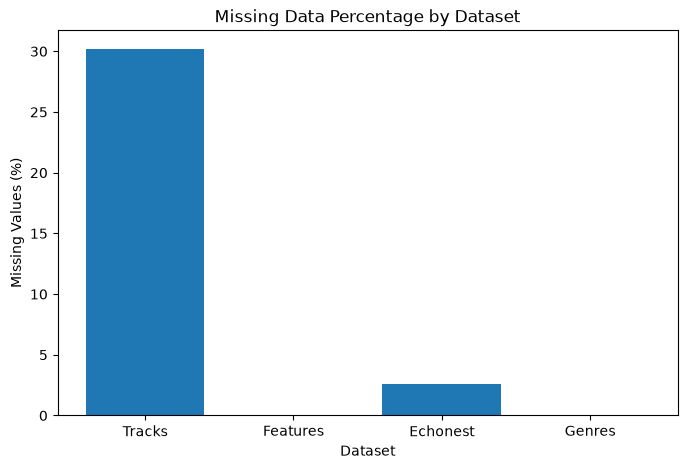

In [56]:

import matplotlib.pyplot as plt

# Tính tỷ lệ dữ liệu thiếu của từng bảng
missing_rate = [
    tracks.isnull().sum().sum() / tracks.size * 100,
    features.isnull().sum().sum() / features.size * 100,
    echonest.isnull().sum().sum() / echonest.size * 100,
    genres.isnull().sum().sum() / genres.size * 100
]

# Vẽ biểu đồ
plt.figure(figsize=(8, 5))
plt.bar(["Tracks", "Features", "Echonest", "Genres"], missing_rate)

plt.title("Missing Data Percentage by Dataset")
plt.xlabel("Dataset")
plt.ylabel("Missing Values (%)")

plt.show()


Bảng tracks có tỷ lệ ô dữ liệu thiếu cao nhất (30,20%), tiếp theo là echonest (2,56%). Hai bảng features và genres không ghi nhận giá trị thiếu.

#### Biểu đồ 10 thuộc tính có tỷ lệ thiếu cao nhất trong tracks.csv
##### Trực quan háo 10 thuộc tính có tỷ lệ thiếu cao nhất trong tracks.csv

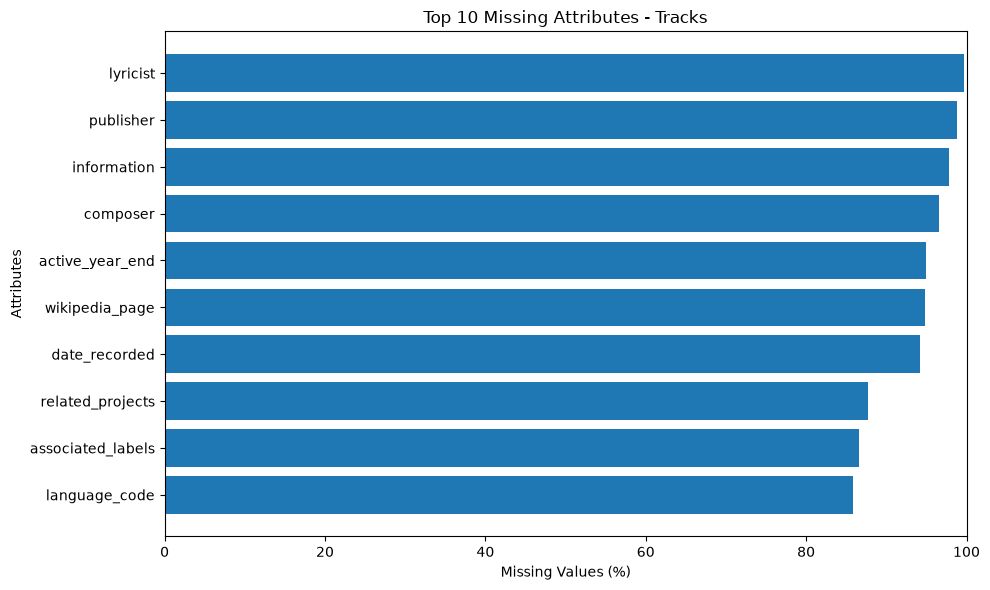

In [57]:


# Lấy 10 thuộc tính thiếu nhiều nhất
missing_tracks = tracks.isnull().sum().sort_values(
    ascending=False
).head(10)

# Chuyển sang tỷ lệ phần trăm
missing_tracks = missing_tracks / len(tracks) * 100

# Vẽ biểu đồ cột ngang
plt.figure(figsize=(10, 6))

plt.barh(
    missing_tracks.index.get_level_values(-1),
    missing_tracks.values
)

plt.gca().invert_yaxis()
plt.title("Top 10 Missing Attributes - Tracks")
plt.xlabel("Missing Values (%)")
plt.ylabel("Attributes")
plt.xlim(0, 100)
plt.tight_layout()

plt.show()



note: missing_tracks.index.get_level_values(-1) lấy tên thuộc tính ở cấp cuối của MultiIndex, chẳng hạn lyricist, publisher, composer thay vì hiện cả ("track", "lyricist")

#### Biểu đồ 10 thuộc tính thiếu nhiều nhất của Enchonest
##### Trực quan hóa những thuộc tính có tỷ lệ cáo nhất trong enchonest.csv

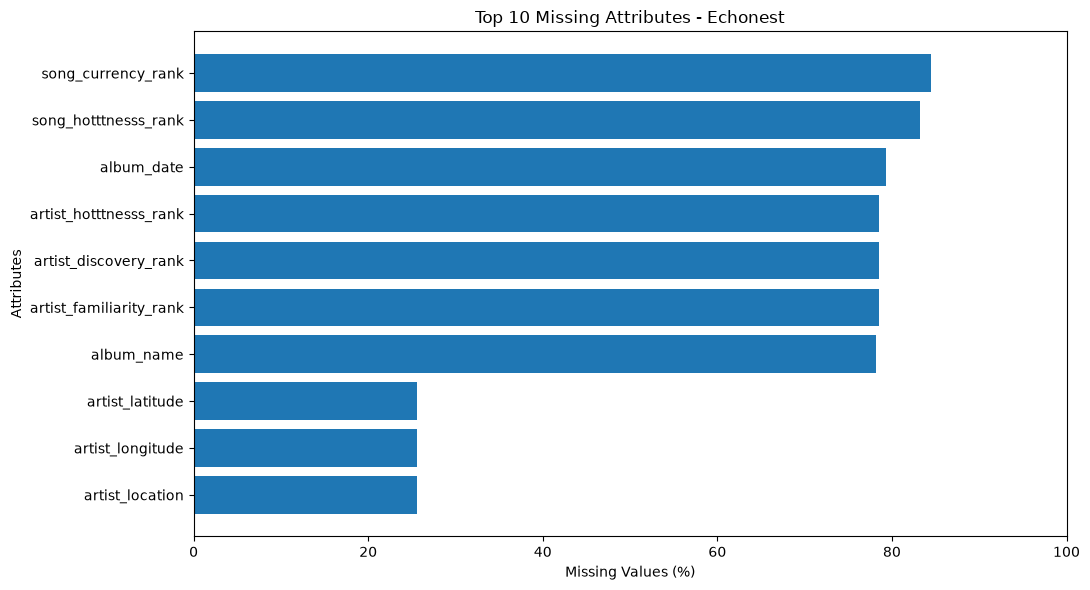

In [58]:

# Lấy 10 thuộc tính thiếu nhiều nhất
missing_echonest = echonest.isnull().sum().sort_values(
    ascending=False
).head(10)

# Chuyển sang tỷ lệ phần trăm
missing_echonest = missing_echonest / len(echonest) * 100

# Vẽ biểu đồ
plt.figure(figsize=(11, 6))

plt.barh(
    missing_echonest.index.get_level_values(-1),
    missing_echonest.values
)

plt.gca().invert_yaxis()
plt.title("Top 10 Missing Attributes - Echonest")
plt.xlabel("Missing Values (%)")
plt.ylabel("Attributes")
plt.xlim(0, 100)
plt.tight_layout()

plt.show()


#### Heatmap dữ liệu thiếu


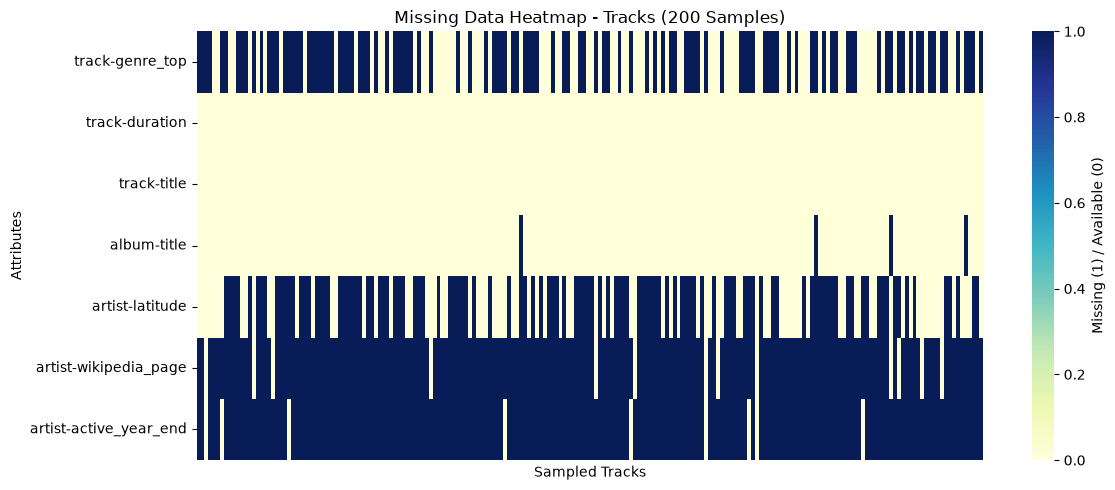

In [59]:

import seaborn as sns

# Chọn một số thuộc tính để quan sát
selected_cols = [
    ("track", "genre_top"),
    ("track", "duration"),
    ("track", "title"),
    ("album", "title"),
    ("artist", "latitude"),
    ("artist", "wikipedia_page"),
    ("artist", "active_year_end")
]

# Lấy mẫu 200 bài hát để biểu đồ dễ quan sát
missing_sample = tracks[selected_cols].sample(
    n=200, random_state=42
)

# Vẽ heatmap dữ liệu thiếu
plt.figure(figsize=(12, 5))

sns.heatmap(
    missing_sample.isnull().transpose(),
    cmap="YlGnBu",
    xticklabels=False,
    cbar_kws={"label": "Missing (1) / Available (0)"}
)

plt.title("Missing Data Heatmap - Tracks (200 Samples)")
plt.xlabel("Sampled Tracks")
plt.ylabel("Attributes")
plt.tight_layout()

plt.show()


Các biểu đồ cho thấy tình trạng dữ liệu thiếu không phân bố đồng đều giữa các bảng trong FMA. Bảng tracks có tỷ lệ thiếu cao nhất, tập trung chủ yếu ở các thuộc tính metadata bổ sung như lyricist, publisher, composer và thông tin nghệ sĩ.

Đối với bảng echonest, dữ liệu thiếu tập trung ở một số thuộc tính thuộc nhóm xếp hạng và metadata. Trong khi đó, hai bảng features và genres không phát hiện giá trị thiếu.

Kết quả trực quan hóa giúp xác định những thuộc tính cần được xem xét khi tiền xử lý. Tuy nhiên, việc loại bỏ hoặc thay thế giá trị thiếu phải dựa trên vai trò và ý nghĩa của từng thuộc tính đối với mục tiêu phân tích.

### 3.3. Kiểm tra dữ liệu trùng lặp


Sử dụng duplicated() để kiểm t ra các bản ghi và giá trị id bị trùng lặp trong bốn bảng dữ liêu FMA
Kiểm tra gồm có hai phần, khóa id và nội dung bản ghi nhằm phát hiện những trường hợp có khả năng sai lệch khi liên kết, thống kê, phân tích dữ liệu

#### Kiểm tra nhanh dữ liệu trùng lặp
##### Kiểm tra số lượng id trùng lặp của cà 4 bảng

In [60]:
duplicate_summary = pd.DataFrame({
    "Bảng": ["Tracks", "Features", "Echonest", "Genres"],
    "Số ID trùng": [
        tracks.index.duplicated().sum(),
        features.index.duplicated().sum(),
        echonest.index.duplicated().sum(),
        genres["genre_id"].duplicated().sum()
    ]
})

display(duplicate_summary)

,Bảng,Số ID trùng
0,Tracks,0
1,Features,0
2,Echonest,0
3,Genres,0


#### Kiểm tra trùng lặp theo nội dung bản ghi
##### Xác định số dòng có nội dung thuộc tính lặp lại trong từng bảng, không xét index

In [61]:

duplicate_rows = pd.DataFrame({
    "Bảng": ["Tracks", "Features", "Echonest", "Genres"],
    "Số dòng trùng nội dung": [
        tracks.duplicated().sum(),
        features.duplicated().sum(),
        echonest.duplicated().sum(),
        genres.duplicated().sum()
    ]
})

display(duplicate_rows)


,Bảng,Số dòng trùng nội dung
0,Tracks,0
1,Features,2111
2,Echonest,0
3,Genres,0


#### Hiển thị chi tiết những id bị trùng
##### Nếu phát hiện id trùng, hiển thị các bản ghi liên quan để quan sát

Tracks:

In [62]:

duplicate_tracks = tracks[
    tracks.index.duplicated(keep=False)
]

display(duplicate_tracks[[
    ("track", "title"),
    ("artist", "name"),
    ("track", "duration")
]].head(10))


,track,artist,track
,title,name,duration
track_id,,,


Genres:

In [63]:

duplicate_genres = genres[
    genres["genre_id"].duplicated(keep=False)
]

display(duplicate_genres.head(10))


,genre_id,#tracks,parent,title,top_level


Features:

In [64]:
display(features[features.index.duplicated(keep=False)].iloc[:10, :5])

Empty DataFrame
Columns: [(chroma_cens, kurtosis, 01), (chroma_cens, kurtosis, 02), (chroma_cens, kurtosis, 03), (chroma_cens, kurtosis, 04), (chroma_cens, kurtosis, 05)]
Index: []

Echonest:

In [65]:
display(echonest[echonest.index.duplicated(keep=False)].iloc[:10, :5])

Empty DataFrame
Columns: [(echonest, audio_features, acousticness), (echonest, audio_features, danceability), (echonest, audio_features, energy), (echonest, audio_features, instrumentalness), (echonest, audio_features, liveness)]
Index: []

Quá trình kiểm tra dữ liệu trùng lặp được thực hiện trên khóa định danh và nội dung bản ghi của bốn bảng FMA. Kết quả giúp đánh giá tính duy nhất của các mã track_id, genre_id và xác định những dòng có thuộc tính giống nhau.

Đối với dữ liệu âm nhạc, sự trùng lặp về tên bài hát, album hoặc nghệ sĩ không nhất thiết phản ánh dữ liệu bị nhập trùng. Do đó, các trường hợp phát hiện được cần xem xét dựa trên khóa định danh và ngữ cảnh dữ liệu trước khi quyết định xử lý

### 3.4. Kiểm tra kiểu dữ liệu và định dạng


Kiểm tra kiểu dữ liệu của các thuộc tính trong bộ dữ liệu FMA để xác định mức độ phù hợp giữa kiểu dữ liệu được nhận diên và ý nghĩa thực tế của từng thuộc tính. Kiểm tra định dạng của một số trường đặc biệt như ngày tháng và danh sách thể loại.

#### Kiểm tra kiểu dữ liệu của bốn bảng
##### Thống kê số lượng thuộc tính theo tình kiểu dữ liệu

In [66]:
for name, df in datasets.items():
    print("\nBảng", name)
    display(df.dtypes.value_counts().to_frame("Số thuộc tính"))


Bảng Tracks


,Số thuộc tính
str,35
int64,15
float64,2



Bảng Features


,Số thuộc tính
float64,518



Bảng Echonest


,Số thuộc tính
float64,244
str,5



Bảng Genres


,Số thuộc tính
int64,4
str,1


#### Kiểm tra kiểu dữ liệu của các thuộc tính tiêu biểu
##### Quan sát cụ thể những thuộc tính định lượng, định tính và ngày tháng để xác định kiểu dữ liệu hiện tại

Tracks:

In [67]:

# Kiểm tra kiểu dữ liệu một số thuộc tính của Tracks
display(tracks[[
    ("track", "title"),
    ("track", "duration"),
    ("track", "listens"),
    ("track", "genre_top"),
    ("track", "genres_all"),
    ("track", "date_created"),
    ("album", "date_released")
]].dtypes.to_frame("Kiểu dữ liệu"))


Kiểu dữ liệu
track title                  str
      duration             int64
      listens              int64
      genre_top              str
      genres_all             str
      date_created           str
album date_released          str

Echonest:

In [68]:

# Kiểm tra kiểu dữ liệu một số thuộc tính của Echonest
display(echonest[[
    ("echonest", "audio_features", "danceability"),
    ("echonest", "audio_features", "tempo"),
    ("echonest", "metadata", "album_date")
]].dtypes.to_frame("Kiểu dữ liệu"))


Kiểu dữ liệu
echonest audio_features danceability      float64
                        tempo             float64
         metadata       album_date            str

#### Kiểm tra định dạng ngày tháng
##### Kiểm tra xem những giá trị không thiếu có thể được nhân diện thành ngày tháng hợp lệ hay không

In [69]:

# Kiểm tra kiểu dữ liệu của các thuộc tính ngày tháng
date_columns = [
    ("track", "date_created"),
    ("track", "date_recorded"),
    ("album", "date_released")
]

display(tracks[date_columns].dtypes.to_frame("Kiểu dữ liệu"))

# Quan sát một số giá trị thực tế
display(tracks[date_columns].head(10))

display(
    tracks[[("track", "date_created")]].dropna().head(10)
)

Kiểu dữ liệu
track date_created           str
      date_recorded          str
album date_released          str

track                                     album
                 date_created        date_recorded        date_released
track_id                                                               
2         2008-11-26 01:48:12  2008-11-26 00:00:00  2009-01-05 00:00:00
3         2008-11-26 01:48:14  2008-11-26 00:00:00  2009-01-05 00:00:00
5         2008-11-26 01:48:20  2008-11-26 00:00:00  2009-01-05 00:00:00
10        2008-11-25 17:49:06  2008-11-26 00:00:00  2008-02-06 00:00:00
20        2008-11-26 01:48:56  2008-01-01 00:00:00  2009-01-06 00:00:00
26        2008-11-26 01:49:05  2008-01-01 00:00:00  2009-01-06 00:00:00
30        2008-11-26 01:49:11  2008-01-01 00:00:00  2009-01-06 00:00:00
46        2008-11-26 01:49:53  2008-01-01 00:00:00  2009-01-06 00:00:00
48        2008-11-26 01:49:56  2008-01-01 00:00:00  2009-01-06 00:00:00
134       2008-11-26 01:43:19  2008-11-26 00:00:00  2009-01-05 00:00:00

,track
,date_created
track_id,
2,2008-11-26 01:48:12
3,2008-11-26 01:48:14
5,2008-11-26 01:48:20
10,2008-11-25 17:49:06
20,2008-11-26 01:48:56
26,2008-11-26 01:49:05
30,2008-11-26 01:49:11
46,2008-11-26 01:49:53


#### Kiểm tra định dang gernes_all

In [72]:

# Kiểm tra định dạng chuỗi danh sách thể loại
genre_values = tracks[("track", "genres_all")].dropna()

valid_format = (
    genre_values.str.startswith("[") &
    genre_values.str.endswith("]")
)

print("Số giá trị đúng dạng dấu ngoặc:", valid_format.sum())
print("Số giá trị không đúng dạng:", (~valid_format).sum())

# Hiển thị một số giá trị không đúng dạng (nếu có)
display(genre_values[~valid_format].head(10))


Số giá trị đúng dạng dấu ngoặc: 106574
Số giá trị không đúng dạng: 0


Series([], Name: (track, genres_all), dtype: str)

**Nhận xét:**

Kết quả kiểm tra cho thấy các bảng dữ liệu FMA sử dụng nhiều kiểu dữ liệu khác nhau. Bảng features gồm các thuộc tính số thực, trong khi tracks và echonest chứa cả dữ liệu định lượng và định tính.

Một số thuộc tính ngày tháng trong tracks hiện được lưu dưới dạng chuỗi. Bên cạnh đó, thuộc tính genres_all cũng được biểu diễn dưới dạng chuỗi chứa danh sách mã thể loại, thay vì cấu trúc danh sách trực tiếp.

Các trường hợp này cần được xem xét và chuyển đổi khi cần thiết nhằm đảm bảo dữ liệu phù hợp với các phương pháp phân tích tiếp theo. Việc kiểm tra ở bước này không làm thay đổi dữ liệu gốc.

### 3.5. Phát hiện giá trị bất thường


Sử dụng biểu đồ Boxplot và phương pháp khoảng tứ phân vị (Interquartile Range – IQR) để phát hiện các giá trị bất thường trong những thuộc tính định lượng của bộ dữ liệu FMA.

Các thuộc tính được lựa chọn gồm thời lượng bài hát (duration), lượt nghe (listens) và số lượt yêu thích (favorites). Việc kiểm tra nhằm xác định những giá trị nằm ngoài khoảng phân bố thông thường, làm cơ sở đánh giá và xử lý dữ liệu ở các bước tiếp theo.

#### Phát hiện outlier bằng Boxplot
##### Quan sát những giá trị nằm ngoài khoảng phân bố thông thường của thời lượng, lượt nghe và lượt yêu thích

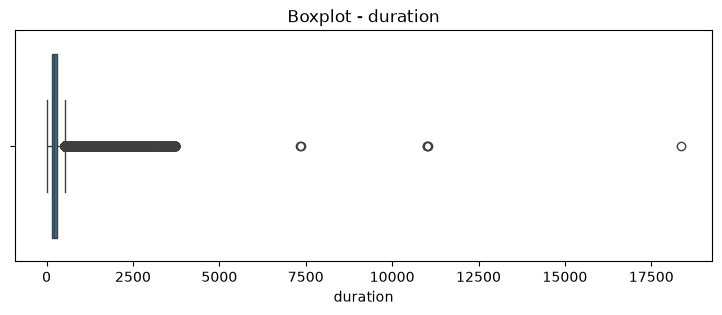

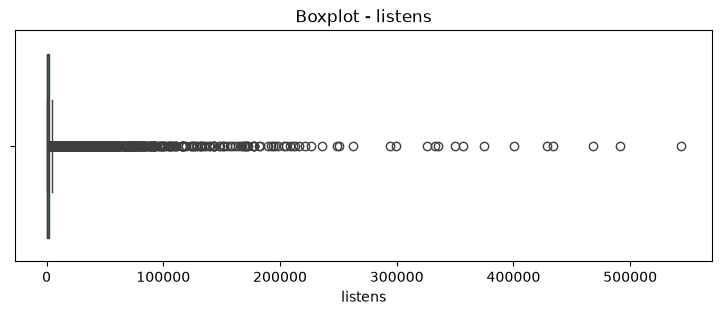

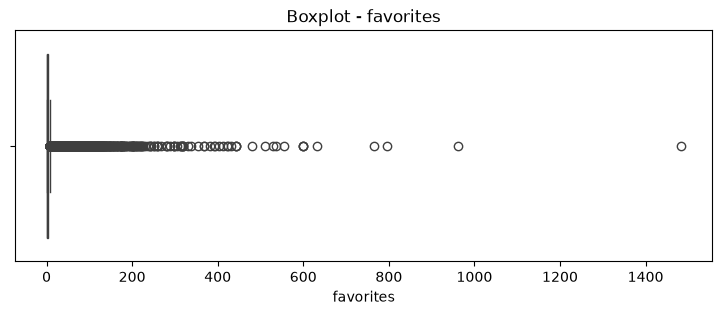

In [73]:

import matplotlib.pyplot as plt
import seaborn as sns

# Lựa chọn các thuộc tính định lượng
outlier_columns = [
    ("track", "duration"),
    ("track", "listens"),
    ("track", "favorites")
]

# Vẽ Boxplot cho từng thuộc tính
for col in outlier_columns:
    plt.figure(figsize=(9, 3))

    sns.boxplot(x=tracks[col])

    plt.title("Boxplot - " + col[1])
    plt.xlabel(col[1])

    plt.show()


#### Phát hiện và thống kê outlier bằng IQR
##### Tính ngưỡng dưới, ngưỡng trên và đếm số lượng bản ghi bất thường của từng thuộc tính



In [74]:

# Thống kê outlier bằng phương pháp IQR
outlier_results = []

for col in outlier_columns:
    Q1 = tracks[col].quantile(0.25)
    Q3 = tracks[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = tracks[
        (tracks[col] < lower) |
        (tracks[col] > upper)
    ]

    outlier_results.append([
        col[1], Q1, Q3, IQR,
        lower, upper, len(outliers)
    ])

outlier_summary = pd.DataFrame(
    outlier_results,
    columns=[
        "Thuộc tính", "Q1", "Q3", "IQR",
        "Ngưỡng dưới", "Ngưỡng trên", "Số outlier"
    ]
)

display(outlier_summary.round(2))


,Thuộc tính,Q1,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Số outlier
0,duration,149.0,305.0,156.0,-85.0,539.0,7709
1,listens,292.0,2018.0,1726.0,-2297.0,4607.0,11391
2,favorites,0.0,3.0,3.0,-4.5,7.5,9232


#### Hiển thị các bản ghi bất thường để kiểm tra
##### Quan sát một số bài hát có thời lượng nằm ngoài ngưởng IQR

In [75]:

# Tính ngưỡng IQR cho thời lượng
Q1 = tracks[("track", "duration")].quantile(0.25)
Q3 = tracks[("track", "duration")].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Lấy những bài hát có thời lượng bất thường
duration_outliers = tracks[
    (tracks[("track", "duration")] < lower) |
    (tracks[("track", "duration")] > upper)
]

display(duration_outliers[[
    ("track", "title"),
    ("artist", "name"),
    ("track", "duration"),
    ("track", "genre_top")
]].head(10))

print("Tổng số bài hát có thời lượng ngoài ngưỡng IQR:", len(duration_outliers))


track          artist  \
                                                      title            name   
track_id                                                                      
135                                            Father's Day        Abominog   
137                                                  Side A          Airway   
138                                                  Side B          Airway   
149                       Outside the window bees buzzed...    Andy Hayleck   
150            ... listening to the sunshine burn the grass    Andy Hayleck   
155                                 Maps of the Stars Homes  Arc and Sender   
238                                          France Attacks       Barnacled   
393       Untitled Boogie (edit), Transfiguration Boogie...    Boogie Witch   
396                                    Juggernaut Soliloquy     Borful Tang   
401                                                 Modesto     Borful Tang   

            track                
         duration     genre_top  
track_id                         
135           837          Rock  
137          1233  Experimental  
138          1231  Experimental  
149           988  Experimental  
150          1182  Experimental  
155           756          Rock  
238           821          Jazz  
393           810          Rock  
396          1137    Electronic  
401          1076    Electronic

Tổng số bài hát có thời lượng ngoài ngưỡng IQR: 7709


#### Kiểm tra giá trị không hợp lệ theo ý nghĩa dữ liệu

In [76]:

# Kiểm tra các giá trị âm không hợp lệ
invalid_values = pd.DataFrame({
    "Thuộc tính": ["duration", "listens", "favorites"],
    "Số giá trị âm": [
        (tracks[("track", "duration")] < 0).sum(),
        (tracks[("track", "listens")] < 0).sum(),
        (tracks[("track", "favorites")] < 0).sum()
    ]
})

display(invalid_values)


,Thuộc tính,Số giá trị âm
0,duration,0
1,listens,0
2,favorites,0


Biểu đồ Boxplot và phương pháp IQR được sử dụng để phát hiện các giá trị nằm ngoài phạm vi phân bố thông thường của những thuộc tính duration, listens và favorites.

Các giá trị bất thường có thể xuất hiện do đặc điểm phân phối của dữ liệu âm nhạc, đặc biệt ở các thuộc tính phản ánh mức độ tương tác của người nghe. Vì vậy, những bản ghi được xác định là outlier cần được xem xét thêm trước khi quyết định xử lý.

Bên cạnh đó, việc kiểm tra các giá trị âm giúp phát hiện những trường hợp có thể không phù hợp với ý nghĩa thực tế của các thuộc tính

### 3.6. Xử lý dữ liệu thiếu, trùng lặp và bất thường


Dựa trên kết quả kiểm tra chất lượng dữ liệu ở các mục 3.1–3.5, tiến hành làm sạch dữ liệu theo đặc điểm và mục đích sử dụng của từng bảng trong FMA.

Quá trình xử lý ưu tiên bảo toàn thông tin bài hát, khóa định danh và các đặc trưng âm thanh hợp lệ. Dữ liệu gốc được giữ nguyên để đối chiếu và đánh giá kết quả trước và sau khi xử lý.

#### Xử lý dữ liệu thiếu trong bảng Tracks

In [77]:

# Tạo bản sao để làm sạch, giữ nguyên dữ liệu gốc
tracks_clean = tracks.copy()

# Điền thông tin chưa xác định cho tên bài hát và album
tracks_clean[("track", "title")] = tracks_clean[
    ("track", "title")
].fillna("Unknown Title")

tracks_clean[("album", "title")] = tracks_clean[
    ("album", "title")
].fillna("Unknown Album")

# Kiểm tra kết quả trước và sau xử lý
compare_missing = pd.DataFrame({
    "Thuộc tính": ["track.title", "album.title"],
    "Trước xử lý": [
        tracks[("track", "title")].isnull().sum(),
        tracks[("album", "title")].isnull().sum()
    ],
    "Sau xử lý": [
        tracks_clean[("track", "title")].isnull().sum(),
        tracks_clean[("album", "title")].isnull().sum()
    ]
})

display(compare_missing)


,Thuộc tính,Trước xử lý,Sau xử lý
0,track.title,1,0
1,album.title,1025,0


Lưu ý: Unknown Title và Unknown Album là giá trị thay thế để hiển thị, không phải tên bài hát hoặc album thực sự. Khi phân tích số lượng bài hát và album có tên xác định, bạn cần phân biệt các giá trị thay thế này.

#### Xử lý thuộc tính thể loại bị thiếu
Trong tracks, cột genre_top thiếu 56.976 giá trị. Nhưng bạn không nên thay các giá trị này bằng Rock hoặc thể loại xuất hiện nhiều nhất. Làm như vậy sẽ tạo ra những nhãn thể loại không có căn cứ, ảnh hưởng đến kết quả phân loại.

Phương án tốt hơn là giữ đầy đủ tracks_clean, đồng thời tạo một tập con dành riêng cho những bài toán cần nhãn thể loại chính.

In [78]:

# Tạo tập dữ liệu chỉ gồm các bài hát có nhãn thể loại chính
tracks_labeled = tracks_clean.dropna(
    subset=[("track", "genre_top")]
).copy()

print("Tổng số bài hát:", len(tracks_clean))
print("Số bài hát có nhãn thể loại:", len(tracks_labeled))
print("Số bài hát chưa có nhãn:", 
      len(tracks_clean) - len(tracks_labeled))


Tổng số bài hát: 106574
Số bài hát có nhãn thể loại: 49598
Số bài hát chưa có nhãn: 56976


Điều cần hiểu: tracks_labeled không thay thế tracks_clean.
- tracks_clean: Tiếp tục sử dụng cho thống kê, khám phá dữ liệu và các bài toán không cần nhãn genre_top.
- tracks_labeled: Dự kiến sử dụng cho Logistic Regression, Naive Bayes, Decision Tree khi cần dự đoán thể loại chính.
Việc lựa chọn đặc trưng và xây dựng bảng huấn luyện cụ thể vẫn sẽ thực hiện ở 3.8. Lựa chọn đặc trưng và chuẩn bị dữ liệu phân tích.

#### Xử lý trùng lặp
Theo kết quả 3.3, cả bốn bảng đều không có khóa định danh trùng lặp. Riêng features có 2.111 dòng giống nhau về nội dung đặc trưng âm thanh.
chưa áp dụng drop_duplicates() trên features.
Lý do là hai bài hát khác nhau vẫn có thể sở hữu những vector đặc trưng giống nhau. Khi xóa dòng theo nội dung, chúng ta có thể làm mất một số track_id cần thiết để liên kết với tracks.

In [79]:

# Kiểm tra tính duy nhất của khóa sau khi xử lý
print("Track ID trùng:", tracks_clean.index.duplicated().sum())
print("Feature ID trùng:", features.index.duplicated().sum())
print("Echonest ID trùng:", echonest.index.duplicated().sum())
print("Genre ID trùng:", genres["genre_id"].duplicated().sum())


Track ID trùng: 0
Feature ID trùng: 0
Echonest ID trùng: 0
Genre ID trùng: 0


**Nhận xét:** Các bảng dữ liệu không phát hiện khóa định danh trùng lặp nên không cần loại bỏ bản ghi theo ID. Đối với bảng `features`, 2.111 trường hợp trùng nội dung đặc trưng được giữ lại để bảo toàn sự liên kết với các bài hát. Các trường hợp này sẽ được xem xét riêng trong quá trình chuẩn bị dữ liệu huấn luyện.

#### Xử lý các giá trị bất thường
Ở 3.5, đã xác nhận duration, listens, favorites không có giá trị âm. Mình đề xuất kiểm tra bổ sung thời lượng bằng 0, vì trường hợp này có thể không phù hợp với việc phân tích độ dài bài hát.

In [80]:

# Kiểm tra bài hát có thời lượng bằng 0
zero_duration = tracks_clean[
    tracks_clean[("track", "duration")] == 0
]

print("Số bài hát có thời lượng bằng 0:", len(zero_duration))

display(zero_duration[[
    ("track", "title"),
    ("track", "duration"),
    ("artist", "name")
]].head(10))


Số bài hát có thời lượng bằng 0: 16


track              artist
                       title duration       name
track_id                                        
8747      Suicidal Sunflower        0  Chamomile
8748              Astrosmash        0  Chamomile
8749            Glowing Eyes        0  Chamomile
8750              Marionette        0  Chamomile
8751          Headless Dolls        0  Chamomile
8752              Monkey Paw        0  Chamomile
8753                   Drunk        0  Chamomile
8754             Nightengale        0  Chamomile
8755                 Alcohol        0  Chamomile
8756              Stargazing        0  Chamomile

In [81]:

# Chỉ chọn các bài hát có thời lượng dương
tracks_valid_duration = tracks_clean[
    tracks_clean[("track", "duration")] > 0
].copy()

print("Tổng số bài hát:", len(tracks_clean))
print("Số bài hát có thời lượng hợp lệ:", len(tracks_valid_duration))


Tổng số bài hát: 106574
Số bài hát có thời lượng hợp lệ: 106558


Quan trọng: tracks_valid_duration chỉ phục vụ những phân tích cần thời lượng dương. Không thay thế toàn bộ tracks_clean bằng bảng này. Nếu xuất hiện giá trị 0, chúng ta ghi nhận là chưa rõ hoặc không phù hợp cho phân tích thời lượng, chứ chưa khẳng định file âm thanh gốc bị lỗi.

Còn các outlier về lượt nghe và lượt yêu thích nên được giữ ở giai đoạn này. Nếu sau này chúng làm phân phối quá lệch hoặc ảnh hưởng mô hình, ta sẽ cân nhắc biến đổi dữ liệu theo từng bài toán.

#### Kiểm tra kết quả trước và sau xử lý
Vì mục 3.9 đã dành riêng cho đánh giá chất lượng sau xử lý, ở đây chỉ cần một bảng đối chiếu ngắn trên tracks.

In [82]:

# So sánh chất lượng bảng Tracks trước và sau xử lý
cleaning_summary = pd.DataFrame({
    "Chỉ tiêu": [
        "Số bản ghi",
        "Số giá trị thiếu",
        "Số Track ID trùng"
    ],
    "Trước xử lý": [
        len(tracks),
        tracks.isnull().sum().sum(),
        tracks.index.duplicated().sum()
    ],
    "Sau xử lý": [
        len(tracks_clean),
        tracks_clean.isnull().sum().sum(),
        tracks_clean.index.duplicated().sum()
    ]
})

display(cleaning_summary)


,Chỉ tiêu,Trước xử lý,Sau xử lý
0,Số bản ghi,106574,106574
1,Số giá trị thiếu,1673813,1672787
2,Số Track ID trùng,0,0


Quá trình làm sạch được thực hiện có chọn lọc dựa trên đặc điểm của bộ dữ liệu FMA. Các giá trị thiếu ở thuộc tính tên bài hát và album được thay thế bằng nhãn thể hiện thông tin chưa xác định, trong khi các thuộc tính metadata khác được giữ nguyên khi chưa có cơ sở bổ sung dữ liệu.

Đối với thuộc tính genre_top, những bản ghi chưa có nhãn được tách khỏi tập dữ liệu phục vụ phân loại, nhưng vẫn được bảo toàn trong tập dữ liệu phân tích tổng thể.

Các bản ghi có đặc trưng âm thanh trùng nhau và các giá trị nằm ngoài ngưỡng IQR chưa bị loại bỏ tự động, do chưa có đủ căn cứ xác định chúng là dữ liệu sai. Phương án này giúp hạn chế mất mát dữ liệu và duy trì sự nhất quán của các khóa liên kết giữa các bảng.

### 3.7. Liên kết và hợp nhất các bảng dữ liệu


Bộ dữ liệu FMA được tổ chức thành nhiều bảng chứa những nhóm thông tin khác nhau. Để phục vụ quá trình phân tích, các bảng được liên kết thông qua khóa định danh track_id và genre_id.

Sử dụng các phương thức join() và merge() trong Pandas để kết hợp dữ liệu, đồng thời kiểm tra tính nhất quán giữa các bảng sau khi liên kết.

#### Kiểm tra khóa liên kết giữa các bảng
##### Xác định số lượng bài hát có track_id xuất hiện đông thời trong các bảng

In [83]:

# Kiểm tra số lượng Track ID khớp giữa các bảng
matching_ids = pd.DataFrame({
    "Bảng liên kết": ["Tracks - Features", "Tracks - Echonest"],
    "Số Track ID khớp": [
        len(tracks_clean.index.intersection(features.index)),
        len(tracks_clean.index.intersection(echonest.index))
    ]
})

display(matching_ids)


,Bảng liên kết,Số Track ID khớp
0,Tracks - Features,106574
1,Tracks - Echonest,13129


#### Hợp nhất Tracks và Features
##### Tạo một bảng phân tích kết hợp thông tin bài hát với các đặc trưng âm nhạc

Chọn thông tin bài hát

In [84]:

# Lựa chọn các thuộc tính cần thiết từ Tracks
track_info = pd.DataFrame({
    "title": tracks_clean[("track", "title")],
    "artist": tracks_clean[("artist", "name")],
    "duration": tracks_clean[("track", "duration")],
    "listens": tracks_clean[("track", "listens")],
    "genre_top": tracks_clean[("track", "genre_top")],
    "genres_all": tracks_clean[("track", "genres_all")]
})

display(track_info.head())

,title,artist,duration,listens,genre_top,genres_all
track_id,,,,,,
2,Food,AWOL,168,1293,Hip-Hop,[21]
3,Electric Ave,AWOL,237,514,Hip-Hop,[21]
5,This World,AWOL,206,1151,Hip-Hop,[21]
10,Freeway,Kurt Vile,161,50135,Pop,[10]
20,Spiritual Level,Nicky Cook,311,361,NaN,"[17, 10, 76, 103]"


Chọn một số đặc trưng âm thanh

In [85]:

# Lấy một số đặc trưng tiêu biểu từ Features
audio_features = pd.DataFrame({
    "chroma_kurtosis": features[("chroma_cens", "kurtosis", "01")],
    "mfcc_mean": features[("mfcc", "mean", "01")],
    "zcr_mean": features[("zcr", "mean", "01")]
})

display(audio_features.head())


,chroma_kurtosis,mfcc_mean,zcr_mean
track_id,,,
2,7.180653,-163.772964,0.085629
3,1.888963,-159.004166,0.084578
5,0.527563,-205.440491,0.053114
10,3.702245,-135.864822,0.077515
20,-0.193837,-135.135895,0.047225


Thực hiện join

In [86]:

# Ghép Tracks và Features theo track_id
analysis_df = track_info.join(audio_features, how="left")

print("Trước khi ghép:", track_info.shape)
print("Sau khi ghép:", analysis_df.shape)

display(analysis_df.head(10))


Trước khi ghép: (106574, 6)
Sau khi ghép: (106574, 9)


,title,artist,duration,listens,genre_top,genres_all,chroma_kurtosis,mfcc_mean,zcr_mean
track_id,,,,,,,,,
2,Food,AWOL,168,1293,Hip-Hop,[21],7.180653,-163.772964,0.085629
3,Electric Ave,AWOL,237,514,Hip-Hop,[21],1.888963,-159.004166,0.084578
5,This World,AWOL,206,1151,Hip-Hop,[21],0.527563,-205.440491,0.053114
10,Freeway,Kurt Vile,161,50135,Pop,[10],3.702245,-135.864822,0.077515
20,Spiritual Level,Nicky Cook,311,361,NaN,"[17, 10, 76, 103]",-0.193837,-135.135895,0.047225
26,Where is your Love?,Nicky Cook,181,193,NaN,"[17, 10, 76, 103]",-0.699535,-233.123718,0.018388
30,Too Happy,Nicky Cook,174,612,NaN,"[17, 10, 76, 103]",-0.721487,-183.218857,0.054417
46,Yosemite,Nicky Cook,104,171,NaN,"[17, 10, 76, 103]",-0.119708,-221.096741,0.036601
48,Light of Light,Nicky Cook,205,173,NaN,"[17, 10, 76, 103]",-1.054053,-219.444641,0.033015


Tại sao chọn how="left"?

Vì chúng ta muốn giữ toàn bộ các bài hát trong track_info, kể cả khi một ID chưa tìm thấy dữ liệu tương ứng ở bảng bên phải.

#### Liên kết với bảng Echonest
##### Bổ sung các thuộc tính dễ giải thích như danceability, energy và tempo để phục vụ một số phân tích về âm nhạc.

Tuy nhiên, echonest chỉ có 13.129 bản ghi, nên mình khuyên tạo một bảng phân tích riêng, thay vì thêm vào analysis_df và khiến phần lớn bài hát có dữ liệu Echonest bị thiếu.

In [87]:

# Lựa chọn một số thuộc tính từ Echonest
echonest_info = pd.DataFrame({
    "danceability": echonest[("echonest", "audio_features", "danceability")],
    "energy": echonest[("echonest", "audio_features", "energy")],
    "tempo": echonest[("echonest", "audio_features", "tempo")]
})

# Ghép với những bài hát có dữ liệu Echonest
analysis_echonest = analysis_df.join(
    echonest_info,
    how="inner"
)

print("Bảng phân tích chính:", analysis_df.shape)
print("Bảng có dữ liệu Echonest:", analysis_echonest.shape)

display(analysis_echonest.head())


Bảng phân tích chính: (106574, 9)
Bảng có dữ liệu Echonest: (13129, 12)


,title,artist,duration,listens,genre_top,genres_all,chroma_kurtosis,mfcc_mean,zcr_mean,danceability,energy,tempo
track_id,,,,,,,,,,,,
2,Food,AWOL,168,1293,Hip-Hop,[21],7.180653,-163.772964,0.085629,0.675894,0.634476,165.922
3,Electric Ave,AWOL,237,514,Hip-Hop,[21],1.888963,-159.004166,0.084578,0.528643,0.817461,126.957
5,This World,AWOL,206,1151,Hip-Hop,[21],0.527563,-205.440491,0.053114,0.745566,0.701470,100.260
10,Freeway,Kurt Vile,161,50135,Pop,[10],3.702245,-135.864822,0.077515,0.658179,0.924525,111.562
134,Street Music,AWOL,207,943,Hip-Hop,[21],0.918445,-207.661484,0.064370,0.513238,0.560410,114.290


Với Echonest, inner join giúp tạo một tập con có dữ liệu từ cả hai phía. Tuy nhiên, các ô thiếu sẵn có bên trong Echonest vẫn được giữ nguyên, không tự động biến mất sau khi join.

#### Liên kết Tracks và Genres qua bảng trung gian
##### Một bài hát có thể gắn nhiều thể loại, nên không thể nối tracks.genres_all trực tiếp với genres.genre_id như quan hệ một–một.

In [88]:

import ast

# Chuyển chuỗi thể loại thành danh sách ID
track_genre = tracks_clean[("track", "genres_all")].apply(
    ast.literal_eval
)

# Tách mỗi thể loại thành một dòng riêng
track_genre = track_genre.explode().dropna().reset_index()

# Đặt tên cột
track_genre.columns = ["track_id", "genre_id"]
track_genre["genre_id"] = track_genre["genre_id"].astype(int)

# Loại bỏ các cặp bài hát - thể loại bị trùng
track_genre = track_genre.drop_duplicates()

display(track_genre.head(10))
print("Số liên kết bài hát - thể loại:", len(track_genre))


,track_id,genre_id
0,2,21
1,3,21
2,5,21
3,10,10
4,20,17
5,20,10
6,20,76
7,20,103
8,26,17
9,26,10


Số liên kết bài hát - thể loại: 349160


- ast.literal_eval(): Chuyển chuỗi như "[12, 25]" thành danh sách Python [12, 25], với cú pháp dữ liệu literal hợp lệ.
- .explode(): Tách một danh sách thành nhiều dòng, mỗi dòng chứa một phần tử.
Nếu phát hiện chuỗi sai định dạng khiến literal_eval() báo lỗi, bạn cần kiểm tra giá trị đó thay vì bỏ qua. Bước 3.4 trước đó mới kiểm tra dấu ngoặc, chưa bảo đảm toàn bộ nội dung đều hợp lệ.

Ghép với bảng Genres

In [89]:

# Ghép mã thể loại với tên thể loại
track_genre_detail = pd.merge(
    track_genre,
    genres[["genre_id", "title"]],
    on="genre_id",
    how="left"
)

display(track_genre_detail.head(10))

print("Số liên kết không tìm thấy thể loại:",
      track_genre_detail["title"].isnull().sum())


,track_id,genre_id,title
0,2,21,Hip-Hop
1,3,21,Hip-Hop
2,5,21,Hip-Hop
3,10,10,Pop
4,20,17,Folk
5,20,10,Pop
6,20,76,Experimental Pop
7,20,103,Singer-Songwriter
8,26,17,Folk
9,26,10,Pop


Số liên kết không tìm thấy thể loại: 0


#### Kiểm tra sau khi hợp nhất


In [90]:

# Kiểm tra kết quả liên kết
join_summary = pd.DataFrame({
    "Bảng dữ liệu": [
        "Tracks gốc",
        "Tracks + Features",
        "Tracks + Features + Echonest",
        "Quan hệ Track - Genre"
    ],
    "Số bản ghi": [
        len(tracks_clean),
        len(analysis_df),
        len(analysis_echonest),
        len(track_genre_detail)
    ]
})

display(join_summary)

print("Track ID trùng trong analysis_df:",
      analysis_df.index.duplicated().sum())


,Bảng dữ liệu,Số bản ghi
0,Tracks gốc,106574
1,Tracks + Features,106574
2,Tracks + Features + Echonest,13129
3,Quan hệ Track - Genre,349160


Track ID trùng trong analysis_df: 0


In [91]:
print("Features không khớp ID:",
      len(tracks_clean.index.difference(features.index)))

print("Echonest không khớp ID:",
      len(echonest.index.difference(tracks_clean.index)))

Features không khớp ID: 0
Echonest không khớp ID: 0


**Nhận xét:**

Quá trình liên kết dữ liệu được thực hiện dựa trên các khóa định danh nhằm kết hợp thông tin bài hát với những đặc trưng âm thanh tương ứng. Bảng `analysis_df` được xây dựng từ `tracks` và một số thuộc tính của `features`, trong khi `analysis_echonest` là tập dữ liệu con phục vụ những phân tích cần thuộc tính từ Echo Nest.

Đối với quan hệ giữa bài hát và thể loại, bảng trung gian `track_genre` được xây dựng từ danh sách `genres_all`, cho phép biểu diễn quan hệ nhiều–nhiều đã mô tả trong ERD.

Các bảng được tổ chức riêng theo mục đích sử dụng nhằm hạn chế việc nhân bản bản ghi hoặc làm mất dữ liệu không cần thiết. Kết quả liên kết sẽ tiếp tục được sử dụng trong bước lựa chọn đặc trưng và chuẩn bị dữ liệu phân tích.

### 3.8. Lựa chọn đặc trưng và chuẩn bị dữ liệu phân tích


Sau quá trình làm sạch và liên kết dữ liệu, tiến hành lựa chọn các thuộc tính phù hợp với từng phương pháp phân tích nhằm giảm bớt dữ liệu không cần thiết và thuận tiện cho việc áp dụng các thuật toán.

Do bộ dữ liệu FMA chứa nhiều nhóm thông tin khác nhau, dữ liệu được chuẩn bị thành các tập riêng cho thống kê, hồi quy, phân loại, phân cụm, giảm chiều và khai phá luật kết hợp. Việc lựa chọn dữ liệu được thực hiện dựa trên ý nghĩa của các thuộc tính và mục tiêu của từng bài toán.

#### Lựa chọn đặc trưng âm thanh

In [92]:

# Lấy các đặc trưng MFCC trung bình
mfcc_features = features["mfcc"]["mean"].copy()
mfcc_features = mfcc_features.add_prefix("mfcc_")

# Kết hợp với các đặc trưng đã chọn ở mục 3.7
ml_features = mfcc_features.join(
    audio_features[["chroma_kurtosis", "zcr_mean"]]
)

print("Kích thước dữ liệu:", ml_features.shape)
display(ml_features.head())


Kích thước dữ liệu: (106574, 22)


,mfcc_01,mfcc_02,mfcc_03,mfcc_04,mfcc_05,mfcc_06,mfcc_07,mfcc_08,mfcc_09,mfcc_10,...,mfcc_13,mfcc_14,mfcc_15,mfcc_16,mfcc_17,mfcc_18,mfcc_19,mfcc_20,chroma_kurtosis,zcr_mean
track_id,,,,,,,,,,,,,,,,,,,,,
2,-163.772964,116.696678,-41.753826,29.144329,-15.050158,18.879372,-8.918165,12.002118,-4.253151,1.359791,...,-6.920971,-3.655366,1.465213,0.201078,3.998204,-2.114676,0.116842,-5.785884,7.180653,0.085629
3,-159.004166,120.158501,-33.233562,47.342003,-6.247318,31.405355,-5.261811,11.618972,-1.595837,5.132730,...,-4.175256,-3.528815,0.274716,-2.270682,1.090475,-2.343884,0.471821,-1.546707,1.888963,0.084578
5,-205.440491,132.215073,-16.085823,41.514759,-7.642954,16.942802,-5.651261,9.569445,0.503157,8.673513,...,-0.340203,2.377888,7.899487,1.947641,7.441950,-1.739911,0.278015,-5.489016,0.527563,0.053114
10,-135.864822,157.040085,-53.453247,17.198896,6.868035,13.934344,-11.749298,8.360711,-5.130381,0.233845,...,-6.218249,1.844195,-4.099704,0.779950,-0.559577,-1.018324,-3.807545,-0.679533,3.702245,0.077515
20,-135.135895,114.814178,12.354540,19.764219,18.670799,19.643862,3.572509,12.124897,-2.285183,8.835210,...,0.214245,3.875917,-0.235324,0.390292,-0.572471,2.779172,2.431258,3.031117,-0.193837,0.047225


Mình cố ý không lấy lại cột mfcc_mean của audio_features, vì giá trị đó đã nằm trong nhóm mfcc_features.

Với cấu trúc FMA, kết quả dự kiến là 20 đặc trưng MFCC trung bình và 2 đặc trưng bổ sung, tức khoảng 22 cột số.

Tại sao chọn MFCC? Vì MFCC biểu diễn các đặc điểm của phổ âm thanh và thường được sử dụng trong phân tích tín hiệu âm thanh. Tuy nhiên, chưa thể kết luận trước rằng bộ 22 đặc trưng này sẽ phân loại thể loại nhạc tốt. Chất lượng thực tế phải được đánh giá khi huấn luyện mô hình.

#### Chuẩn bị dữ liệu cho bài toán phân loại
##### Tạo bảng có cả đặc trưng đầu vào và nhẵn thể loại chính

In [93]:

# Ghép đặc trưng âm thanh với nhãn thể loại
classification_df = ml_features.join(
    track_info[["genre_top"]]
)

# Chỉ giữ những bài hát có nhãn thể loại
classification_df = classification_df.dropna(
    subset=["genre_top"]
)

print("Dữ liệu phân loại:", classification_df.shape)

display(classification_df.head())
display(
    classification_df["genre_top"]
    .value_counts()
    .to_frame("Số bài hát")
)


Dữ liệu phân loại: (49598, 23)


,mfcc_01,mfcc_02,mfcc_03,mfcc_04,mfcc_05,mfcc_06,mfcc_07,mfcc_08,mfcc_09,mfcc_10,...,mfcc_14,mfcc_15,mfcc_16,mfcc_17,mfcc_18,mfcc_19,mfcc_20,chroma_kurtosis,zcr_mean,genre_top
track_id,,,,,,,,,,,,,,,,,,,,,
2,-163.772964,116.696678,-41.753826,29.144329,-15.050158,18.879372,-8.918165,12.002118,-4.253151,1.359791,...,-3.655366,1.465213,0.201078,3.998204,-2.114676,0.116842,-5.785884,7.180653,0.085629,Hip-Hop
3,-159.004166,120.158501,-33.233562,47.342003,-6.247318,31.405355,-5.261811,11.618972,-1.595837,5.132730,...,-3.528815,0.274716,-2.270682,1.090475,-2.343884,0.471821,-1.546707,1.888963,0.084578,Hip-Hop
5,-205.440491,132.215073,-16.085823,41.514759,-7.642954,16.942802,-5.651261,9.569445,0.503157,8.673513,...,2.377888,7.899487,1.947641,7.441950,-1.739911,0.278015,-5.489016,0.527563,0.053114,Hip-Hop
10,-135.864822,157.040085,-53.453247,17.198896,6.868035,13.934344,-11.749298,8.360711,-5.130381,0.233845,...,1.844195,-4.099704,0.779950,-0.559577,-1.018324,-3.807545,-0.679533,3.702245,0.077515,Pop
134,-207.661484,125.521309,-33.416592,32.260929,8.074771,15.349553,-4.074179,10.281721,5.245880,7.009424,...,3.134924,4.580719,-0.493938,0.490930,-2.718678,-0.770406,-3.995600,0.918445,0.064370,Hip-Hop


,Số bài hát
genre_top,
Rock,14182
Experimental,10608
Electronic,9372
Hip-Hop,3552
Folk,2803
Pop,2332
Instrumental,2079
International,1389
Classical,1230


Ở đây:
- Các cột âm thanh là đặc trưng đầu vào.
- genre_top là biến mục tiêu.
- Những bài không có genre_top chỉ bị loại khỏi tập phân loại, không bị xóa khỏi dữ liệu FMA gốc

In [94]:

# Tách biến đầu vào và biến mục tiêu
X_classification = classification_df[ml_features.columns]
y_classification = classification_df["genre_top"]

print("X:", X_classification.shape)
print("y:", y_classification.shape)


X: (49598, 22)
y: (49598,)


X_classification sẽ được sử dụng cho Naive Bayes và Decision Tree.

Riêng Logistic Regression, mình khuyên bắt đầu bằng bài toán nhị phân Rock / Không phải Rock, vì dễ hiểu và dễ giải thích:

In [95]:
y_logistic = (y_classification == "Rock").astype(int)

display(y_logistic.value_counts().to_frame("Số bài hát"))

,Số bài hát
genre_top,
0,35416
1,14182


#### Chuẩn bị dữ liệu hồi quy tuyến tính
Hồi quy tuyến tính cần một biến mục tiêu định lượng.

Với FMA, mình đề xuất thử bài toán: Các đặc trưng âm thanh và thời lượng bài hát có thể giải thích được bao nhiêu sự thay đổi của lượt nghe?

Đây là bài toán hồi quy thăm dò, không phải lời khẳng định rằng đặc trưng âm thanh quyết định độ phổ biến.

In [96]:

# Chọn biến cho hồi quy tuyến tính
regression_df = analysis_df[[
    "listens",
    "duration",
    "chroma_kurtosis",
    "mfcc_mean",
    "zcr_mean"
]].copy()

# Chỉ sử dụng những bài hát có thời lượng dương
regression_df = regression_df[
    regression_df["duration"] > 0
]

print("Dữ liệu hồi quy:", regression_df.shape)

display(regression_df.head())
display(regression_df.isnull().sum().to_frame("Số giá trị thiếu"))


Dữ liệu hồi quy: (106558, 5)


,listens,duration,chroma_kurtosis,mfcc_mean,zcr_mean
track_id,,,,,
2,1293,168,7.180653,-163.772964,0.085629
3,514,237,1.888963,-159.004166,0.084578
5,1151,206,0.527563,-205.440491,0.053114
10,50135,161,3.702245,-135.864822,0.077515
20,361,311,-0.193837,-135.135895,0.047225


,Số giá trị thiếu
listens,0
duration,0
chroma_kurtosis,0
mfcc_mean,0
zcr_mean,0


Trong đó:
Vai trò	Thuộc tính
Biến mục tiêu y	listens
Biến đầu vào X	duration, chroma_kurtosis, mfcc_mean, zcr_mean

Nhờ kết quả 3.6, chúng ta đã biết có 16 bài hát có thời lượng bằng 0. Việc lọc những bài đó ở đây phù hợp vì duration được dùng làm biến đầu vào.

Điểm cần nhớ: listens là dữ liệu đếm và thường có phân phối lệch mạnh, nên hồi quy tuyến tính có thể cho kết quả không tốt hoặc vi phạm một số giả định. Ở Chương 6, bạn cần kiểm tra kết quả và phần dư trước khi đưa ra kết luận; nếu cần có thể thử biến đổi mục tiêu hoặc thay đổi bài toán.

#### Chuẩn bị dữ liệu cho K-means và PCA
Đây lại là phần khá đơn giản.

Vì K-Means và PCA làm việc trên các đặc trưng số, chúng ta có thể sử dụng chính ml_features đã tạo ở 3.8.1.

In [97]:

# Tập đặc trưng dùng cho K-Means và PCA
clustering_df = ml_features.copy()

print("Kích thước dữ liệu:", clustering_df.shape)
print("Số giá trị thiếu:", clustering_df.isnull().sum().sum())

display(clustering_df.head())


Kích thước dữ liệu: (106574, 22)
Số giá trị thiếu: 0


,mfcc_01,mfcc_02,mfcc_03,mfcc_04,mfcc_05,mfcc_06,mfcc_07,mfcc_08,mfcc_09,mfcc_10,...,mfcc_13,mfcc_14,mfcc_15,mfcc_16,mfcc_17,mfcc_18,mfcc_19,mfcc_20,chroma_kurtosis,zcr_mean
track_id,,,,,,,,,,,,,,,,,,,,,
2,-163.772964,116.696678,-41.753826,29.144329,-15.050158,18.879372,-8.918165,12.002118,-4.253151,1.359791,...,-6.920971,-3.655366,1.465213,0.201078,3.998204,-2.114676,0.116842,-5.785884,7.180653,0.085629
3,-159.004166,120.158501,-33.233562,47.342003,-6.247318,31.405355,-5.261811,11.618972,-1.595837,5.132730,...,-4.175256,-3.528815,0.274716,-2.270682,1.090475,-2.343884,0.471821,-1.546707,1.888963,0.084578
5,-205.440491,132.215073,-16.085823,41.514759,-7.642954,16.942802,-5.651261,9.569445,0.503157,8.673513,...,-0.340203,2.377888,7.899487,1.947641,7.441950,-1.739911,0.278015,-5.489016,0.527563,0.053114
10,-135.864822,157.040085,-53.453247,17.198896,6.868035,13.934344,-11.749298,8.360711,-5.130381,0.233845,...,-6.218249,1.844195,-4.099704,0.779950,-0.559577,-1.018324,-3.807545,-0.679533,3.702245,0.077515
20,-135.135895,114.814178,12.354540,19.764219,18.670799,19.643862,3.572509,12.124897,-2.285183,8.835210,...,0.214245,3.875917,-0.235324,0.390292,-0.572471,2.779172,2.431258,3.031117,-0.193837,0.047225


Tại sao không có genre_top?

Vì K-Means là phương pháp học không giám sát. Chúng ta muốn phân nhóm bài hát dựa trên dữ liệu âm thanh, không để nhãn thể loại có sẵn quyết định kết quả.

Sau khi phân cụm, bạn vẫn có thể liên kết kết quả với genre_top để quan sát mức độ tương ứng giữa cụm và thể loại.

Đối với PCA, các đặc trưng sẽ được chuẩn hóa trước khi giảm chiều. Nhưng mình khuyên chưa dùng StandardScaler trong mục 3.8.
Chúng ta sẽ triển khai trong Chương 7. Đặc biệt, với mô hình có train/test, bộ chuẩn hóa phải được học từ dữ liệu huấn luyện để tránh rò rỉ thông tin sang tập kiểm tra.

Nếu chạy K-Means trên 106.574 bài hát quá nặng, bạn có thể sử dụng mẫu nhỏ hơn cho thử nghiệm, ví dụ:

In [ ]:
clustering_sample = clustering_df.sample(
    n=10000,
    random_state=42
)

#### Dữ liệu cho luật kết hợp và Echonest
Ở đây không cần tạo thêm DataFrame mới vì bạn đã chuẩn bị chúng từ mục 3.7.
DataFrame đã có	Sử dụng
track_genre	Dữ liệu bài hát và thể loại cho Association Rules
track_genre_detail	Tra cứu tên thể loại để giải thích các luật
analysis_echonest	Phân tích tempo, energy và danceability
analysis_df	Thống kê mô tả và EDA trên toàn bộ FMA

Mình muốn nhấn mạnh một chi tiết về luật kết hợp: mỗi bài hát sẽ là một giao dịch, các genre_id là những mục xuất hiện trong giao dịch. Không coi mỗi dòng của track_genre là một giao dịch độc lập.

Ngoài ra, genres_all có chứa quan hệ thể loại phân cấp. Khi phân tích luật kết hợp, cần phân biệt luật đồng xuất hiện thực sự với những luật gần như tất yếu do thể loại cha–con.

**Nhận xét:**

Dữ liệu FMA được chuẩn bị thành các tập phân tích riêng nhằm đáp ứng đặc điểm của từng phương pháp thống kê và học máy.

Đối với các bài toán phân loại, tập dữ liệu được lựa chọn dựa trên những bài hát có nhãn `genre_top`. Các bài toán phân cụm và PCA sử dụng đặc trưng âm thanh định lượng, trong khi hồi quy tuyến tính sử dụng các thuộc tính được lựa chọn để nghiên cứu mối quan hệ với lượt nghe.

Việc tổ chức dữ liệu theo từng mục tiêu giúp hạn chế sử dụng các thuộc tính không phù hợp, bảo toàn dữ liệu gốc và thuận tiện cho quá trình phân tích, huấn luyện, đánh giá mô hình ở các chương tiếp theo.

### 3.9. Đánh giá chất lượng dữ liệu sau xử lý

## 4. Thống kê mô tả và trực quan hóa dữ liệu

### 4.1. Các đại lượng thống kê mô tả


### 4.2. Phân tích phân bố thể loại âm nhạc


### 4.3. Phân tích đặc trưng âm thanh


### 4.4. Phân tích mối quan hệ giữa các biến


### 4.5. Trực quan hóa bằng các biểu đồ thống kê


### 4.6. Nhận xét và phát hiện từ dữ liệu

## 5. Phân phối xác suất và kiểm định giả thuyết

### 5.1. Phân phối nhị thức (Binomial Distribution)


### 5.2. Phân phối Poisson


### 5.3. Kiểm định T-Test


### 5.4. Kiểm định Z-Test


### 5.5. Tổng hợp và diễn giải kết quả kiểm định

## 6. Phân tích hổi quy

### 6.1. Hồi quy tuyến tính (Linear Regression)


### 6.2. Hồi quy Logistic (Logistic Regression)


### 6.3. Đánh giá và nhận xét kết quả

## 7. Phân cụm, phân loại và giảm chiều dữ liệu

### 7.1. Phân cụm K-Means


### 7.2. Phân loại Naive Bayes


### 7.3. Phân loại bằng cây quyết định (Decision Tree)


### 7.4. Phân tích thành phần chính (PCA)


### 7.5. So sánh và đánh giá các mô hình

## 8. Khai phá luận kết hợp

### 8.1. Xây dựng dữ liệu giao dịch


### 8.2. Thuật toán Apriori


### 8.3. Phân tích Support, Confidence và Lift


### 8.4. Diễn giải các luật kết hợp

## 9. Kết luận và hướng phát triển


### 9.1. Tổng hợp các kết quả chính


### 9.2. Hạn chế của nghiên cứu


### 9.3. Hướng phát triển trong tương lai